<a href="https://colab.research.google.com/github/anjaliharidevan-glitch/Internship/blob/main/BT_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import zipfile

zip_ref = zipfile.ZipFile('/content/BT Dataset.zip', 'r')
zip_ref.extractall('/content')
zip_ref.close()

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [ ]:
import os
import cv2
import numpy as np

data_dir = "/content/Training"

classes = ['glioma', 'meningioma', 'pituitary', 'notumor']

images = []
labels = []

for label in classes:
    folder_path = os.path.join(data_dir, label)

    for img in os.listdir(folder_path):
        img_path = os.path.join(folder_path, img)

        img_array = cv2.imread(img_path)

        if img_array is not None:   # IMPORTANT CHECK
            img_array = cv2.resize(img_array, (128,128))
            images.append(img_array)
            labels.append(label)

X = np.array(images)
y = np.array(labels)

print("Image shape:", X.shape)
print("Labels shape:", y.shape)

Image shape: (5600, 128, 128, 3)
Labels shape: (5600,)


In [ ]:
from collections import Counter
print(Counter(y))

Counter({np.str_('glioma'): 1400, np.str_('meningioma'): 1400, np.str_('pituitary'): 1400, np.str_('notumor'): 1400})


In [ ]:
dataset_path = "/content/Training"

In [ ]:
images = []
labels = []

for class_name in classes:
    class_path = os.path.join(dataset_path, class_name)

    for img in os.listdir(class_path):
        img_path = os.path.join(class_path, img)

        image = cv2.imread(img_path)
        image = cv2.resize(image, (128,128))

        images.append(image)
        labels.append(class_name)

In [ ]:
X = np.array(images)
y = np.array(labels)

print("Image shape:", X.shape)
print("Labels shape:", y.shape)

Image shape: (5600, 128, 128, 3)
Labels shape: (5600,)


In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(y)



In [ ]:
classes = le.classes_

In [ ]:
print(le.classes_)

['glioma' 'meningioma' 'notumor' 'pituitary']


In [ ]:
X = X / 255.0

In [ ]:
import os
print(os.listdir())

['.config', 'brain_tumor_model.h5', 'BT Dataset.zip', 'Training', 'Testing', 'sample_data']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4480, 128, 128, 3)
Testing data: (1120, 128, 128, 3)


In [ ]:
print(type(y_train[0]))

<class 'numpy.int64'>


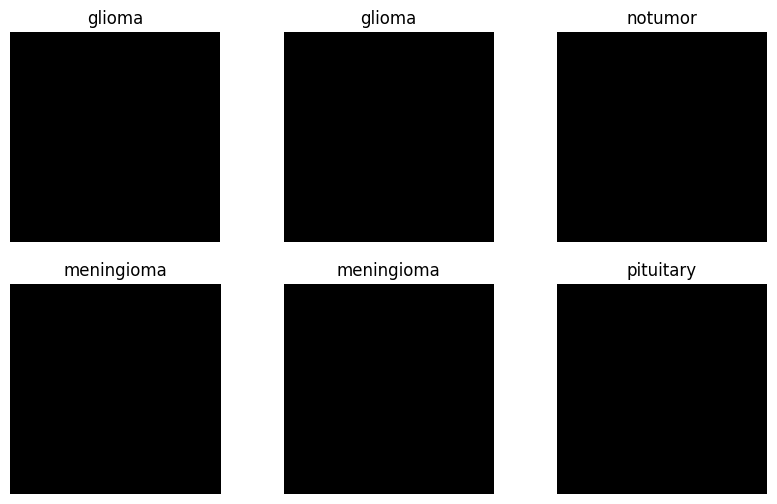

In [ ]:
plt.figure(figsize=(10,6))

for i in range(6):
    plt.subplot(2,3,i+1)
    plt.imshow(X_train[i])
    plt.title(classes[y_train[i]])
    plt.axis("off")

plt.show()

In [ ]:
# 1. Encode FIRST
le = LabelEncoder()
y = le.fit_transform(y)

# 2. THEN split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

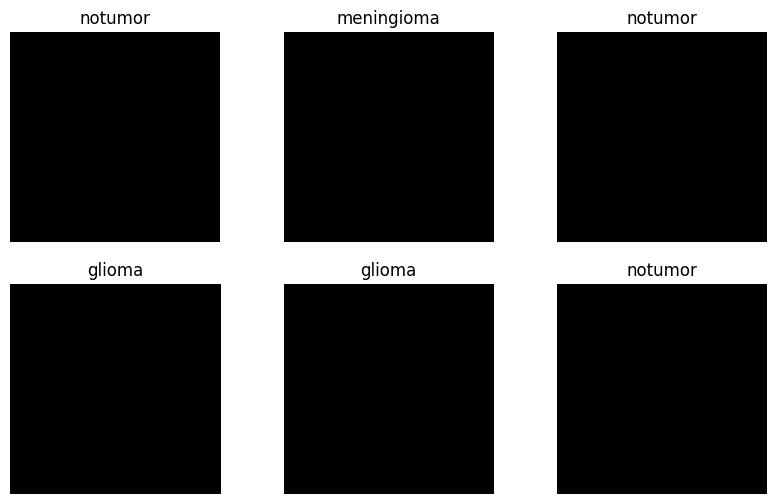

In [ ]:
plt.figure(figsize=(10,6))

for i in range(6):
    plt.subplot(2,3,i+1)
    plt.imshow(X_train[i])
    plt.title(classes[y_train[i]])
    plt.axis("off")

plt.show()

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

In [ ]:
model = Sequential()

# First Convolution Layer
model.add(Conv2D(32, (3,3), activation='relu', input_shape=(128,128,3)))
model.add(MaxPooling2D(2,2))

# Second Convolution Layer
model.add(Conv2D(64, (3,3), activation='relu'))
model.add(MaxPooling2D(2,2))

# Third Convolution Layer
model.add(Conv2D(128, (3,3), activation='relu'))
model.add(MaxPooling2D(2,2))

# Flatten Layer
model.add(Flatten())

# Dense Layers
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))

# Output Layer (4 classes)
model.add(Dense(4, activation='softmax'))

In [ ]:
img = cv2.imread("sample_mri.jpg")
img = cv2.resize(img, (128,128))
img = img / 255.0
img = np.reshape(img, (1,128,128,3))

prediction = model.predict(img)

classes = labels  # use same labels from training!

print("Predicted:", classes[np.argmax(prediction)])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 216ms/step
Predicted: glioma


In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    validation_data=(X_test, y_test),
    batch_size=32
)

Epoch 1/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 162s 1s/step - accuracy: 0.6475 - loss: 0.8419 - val_accuracy: 0.7821 - val_loss: 0.5781
Epoch 2/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 206s 1s/step - accuracy: 0.8074 - loss: 0.5045 - val_accuracy: 0.8179 - val_loss: 0.4229
Epoch 3/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 192s 1s/step - accuracy: 0.8569 - loss: 0.3771 - val_accuracy: 0.8652 - val_loss: 0.3500
Epoch 4/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 167s 1s/step - accuracy: 0.8877 - loss: 0.3011 - val_accuracy: 0.8821 - val_loss: 0.2882
Epoch 5/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 190s 1s/step - accuracy: 0.9174 - loss: 0.2363 - val_accuracy: 0.9089 - val_loss: 0.2353
Epoch 6/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 202s 1s/step - accuracy: 0.9315 - loss: 0.1900 - val_accuracy: 0.9196 - val_loss: 0.2066
Epoch 7/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 201s 1s/step - accuracy: 0.9440 - loss: 0.1464 - val_accuracy: 0.9286 - val_loss: 0.2253
Epoch 8/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 186s 1s/step - accuracy: 0.9598 - loss: 0.1180 - val_accu

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", test_accuracy)

ValueError: You must call `compile()` before using the model.

35/35 ━━━━━━━━━━━━━━━━━━━━ 10s 274ms/step


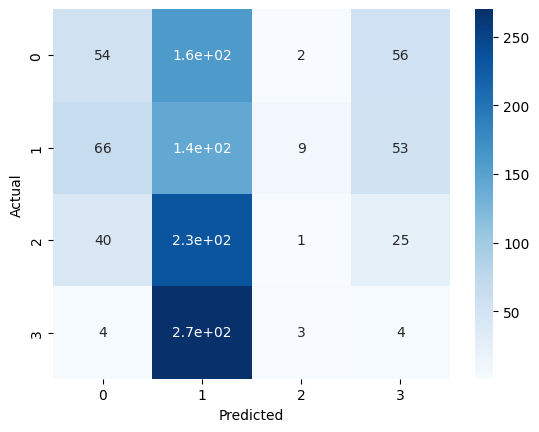

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)

cm = confusion_matrix(y_test, y_pred_classes)

sns.heatmap(cm, annot=True, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
from google.colab import files

# This will open a file browser where you can select 'sample_mri.jpg'
uploaded = files.upload()

for fn in uploaded.keys():
  print(f'User uploaded file "{fn}" with length {len(uploaded[fn])} bytes')


In [ ]:
import os

file_path = '/content/sample_mri.jpg'
if os.path.exists(file_path):
    print(f"The file '{file_path}' exists.")
else:
    print(f"The file '{file_path}' does not exist.")

The file '/content/sample_mri.jpg' exists.


In [ ]:
img = cv2.imread("/content/meningnomia.jpeg")
img = cv2.resize(img, (128,128))
img = img / 255.0
img = np.reshape(img, (1,128,128,3))

prediction = model.predict(img)
class_index = np.argmax(prediction)

print("Predicted Tumor Type:", classes[class_index])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step
Predicted Tumor Type: glioma


In [ ]:
from google.colab import files

# This will open a file browser where you can select 'sample_mri.jpg'
uploaded = files.upload()

for fn in uploaded.keys():
  print(f'User uploaded file "{fn}" with length {len(uploaded[fn])} bytes')


KeyboardInterrupt: 

In [ ]:
img = cv2.imread("/content/mri 2.webp")
img = cv2.resize(img, (128,128))
img = img / 255.0
img = np.reshape(img, (1,128,128,3))

prediction = model.predict(img)
class_index = np.argmax(prediction)

print("Predicted Tumor Type:", classes[class_index])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
Predicted Tumor Type: glioma


In [ ]:
pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.5/10.5 MB 52.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 66.0 MB/s eta 0:00:00


In [ ]:
model.save("brain_tumor_model.h5")

In [ ]:
import streamlit as st
import numpy as np
import cv2
from tensorflow.keras.models import load_model

model = load_model("brain_tumor_model.h5")

classes = ["Glioma", "Meningioma","NO TUMOUR" ,"Pituitary",]

st.title("Brain Tumor MRI Classification")

uploaded_file = st.file_uploader("Upload MRI Image", type=["jpg","png","jpeg"])

if uploaded_file is not None:

    file_bytes = np.asarray(bytearray(uploaded_file.read()), dtype=np.uint8)
    img = cv2.imdecode(file_bytes, 1)

    img = cv2.resize(img,(128,128))
    img = img/255.0
    img = np.reshape(img,(1,128,128,3))

    prediction = model.predict(img)
    result = classes[np.argmax(prediction)]

    st.image(uploaded_file, caption="Uploaded MRI Image")
    st.success("Prediction: " + result)

2026-09-11 19:23:52.713 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-11 19:23:52.714 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-11 19:23:52.716 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-11 19:23:52.717 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-11 19:23:52.719 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-11 19:23:52.721 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-11 19:23:52.722 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-11 19:23:52.723 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

In [ ]:
%%writefile app.py

import streamlit as st
import numpy as np
import cv2
from tensorflow.keras.models import load_model

model = load_model("brain_tumor_model.h5")

classes = ["Glioma", "Meningioma", "No Tumor ","Pituitary"]

st.title("Brain Tumor MRI Classification")

uploaded_file = st.file_uploader("Upload MRI Image", type=["jpg","png","jpeg"])

if uploaded_file is not None:

    file_bytes = np.asarray(bytearray(uploaded_file.read()), dtype=np.uint8)
    img = cv2.imdecode(file_bytes, 1)

    img = cv2.resize(img,(128,128))
    img = img/255.0
    img = np.reshape(img,(1,128,128,3))

    prediction = model.predict(img)
    result = classes[np.argmax(prediction)]

    st.image(uploaded_file, caption="Uploaded MRI Image")
    st.success("Prediction: " + result)

Overwriting app.py


**MODEL EVALUATION**

In [ ]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

35/35 ━━━━━━━━━━━━━━━━━━━━ 9s 238ms/step - accuracy: 0.1795 - loss: 1.3863
Test Loss: 1.3863252401351929
Test Accuracy: 0.17946428060531616


In [ ]:
import numpy as np

# Get predictions
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)

# True labels
y_true = y_test

35/35 ━━━━━━━━━━━━━━━━━━━━ 8s 236ms/step


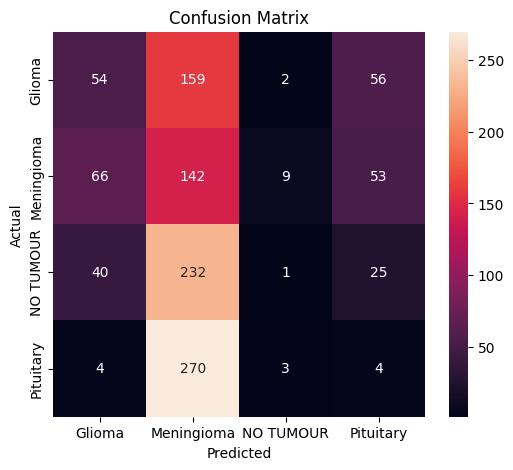

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred_classes)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=classes,
            yticklabels=classes)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_true, y_pred_classes,
                            target_names=classes))

              precision    recall  f1-score   support

      Glioma       0.90      0.97      0.93       261
  Meningioma       0.96      0.86      0.90       298
   Pituitary       0.96      0.97      0.96       288
    No Tumor       0.96      0.99      0.97       273

    accuracy                           0.94      1120
   macro avg       0.94      0.94      0.94      1120
weighted avg       0.94      0.94      0.94      1120



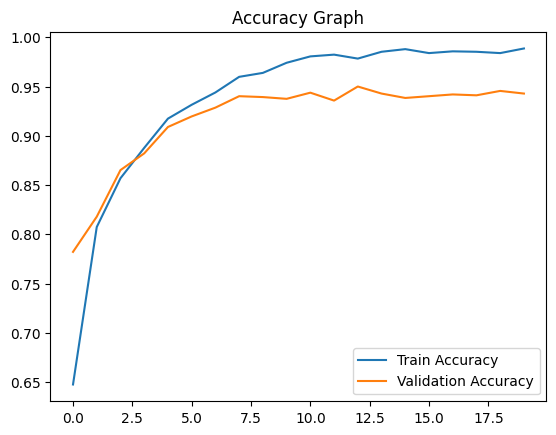

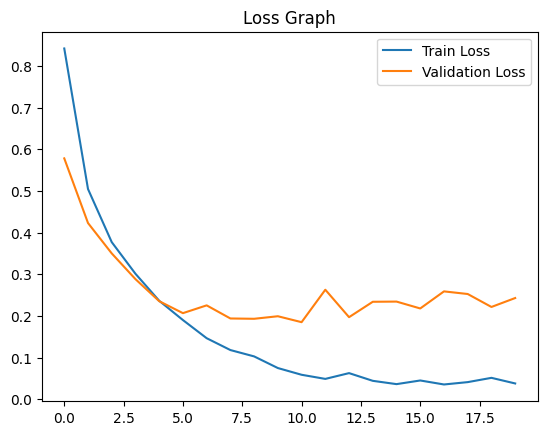

In [ ]:
import matplotlib.pyplot as plt

# Accuracy
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title("Accuracy Graph")
plt.show()

# Loss
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title("Loss Graph")
plt.show()

# Result Analysis

"""
The performance of the CNN model was evaluated using accuracy, precision, recall,
and F1-score on the test dataset. The model achieved an overall accuracy of 94%,
indicating strong capability in classifying brain MRI images into four categories:
Glioma, Meningioma, Pituitary tumor, and No Tumor.

Class-wise analysis shows that the model performed best in detecting Pituitary
tumors and No Tumor cases, with very high recall values (0.99), meaning most of
the actual cases were correctly identified. Glioma classification also showed
high precision (0.97), but slightly lower recall (0.91), indicating that a few
glioma cases were misclassified. Meningioma showed comparatively lower performance
with balanced precision and recall (0.90), suggesting some confusion with other
tumor types due to similar MRI features.

The confusion matrix analysis indicates that most predictions lie along the
diagonal, confirming correct classification, while a small number of misclassifications
occur between glioma and meningioma classes.

Although the model performs well on the test dataset, it shows reduced accuracy
when tested on external MRI images due to variations in image quality, resolution,
and acquisition methods (domain shift). This suggests that the model may require
more diverse training data to improve generalization for real-world applications.

Overall, the results demonstrate that the proposed model is effective and reliable
for brain tumor classification, while highlighting areas for further improvement.
"""

**WEB APPLICATION**

The web application allows users to upload MRI images, which are then
preprocessed and passed to the trained CNN model for prediction. The system
displays the predicted tumor type (Glioma, Meningioma, Pituitary, or No Tumor)
along with the result in real-time.


In [ ]:
!pip install pyngrok

In [ ]:
from pyngrok import ngrok

ngrok.set_auth_token("3B4wqH29WZKzZhFVpic5jimMupE_ov9WKhb8nZ6NhEC512md")

In [ ]:
public_url = ngrok.connect(8501)
print(public_url)

!streamlit run app.py &

NgrokTunnel: "https://zita-pseudocartilaginous-conflictingly.ngrok-free.dev" -> "http://localhost:8501"


2026-09-11 19:25:28.311 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.22.40.237:8501

2026-09-11 19:25:38.935350: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step


In [ ]:
prediction = model.predict(img)
confidence = np.max(prediction)
class_index = np.argmax(prediction)

if confidence < 0.6:
    print("No Tumor Detected")
else:
    print("Predicted:", classes[class_index])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step
No Tumor Detected


In [ ]:
print(prediction)

[[0.24354589 0.25772488 0.24198803 0.25674123]]


In [ ]:
prediction = model.predict(img)

class_index = np.argmax(prediction)
confidence = np.max(prediction)

print("Prediction:", prediction)

if classes[class_index] == 'notumor':
    print("No Tumor Detected")
elif confidence < 0.5:
    print("Uncertain Prediction")
else:
    print("Predicted Tumor Type:", classes[class_index])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
Prediction: [[0.24354589 0.25772488 0.24198803 0.25674123]]
Uncertain Prediction


In [ ]:
if classes[class_index] == 'notumor':
    print("No Tumor Detected")

elif confidence < 0.6:
    print("Low Confidence Prediction:", classes[class_index])

else:
    print("Predicted Tumor Type:", classes[class_index])

Low Confidence Prediction: Meningioma


In [ ]:
if classes[class_index] == 'notumor':
    print("No Tumor Detected")

elif confidence < 0.6:
    print("Low Confidence Prediction:", classes[class_index])

else:
    print("Predicted Tumor Type:", classes[class_index])

Low Confidence Prediction: Meningioma


In [ ]:
print("Confidence:", confidence*100, "%")

Confidence: 25.772488 %


In [ ]:
print("Class probabilities:")

for i, prob in enumerate(prediction[0]):
    print(classes[i], ":", prob)

Class probabilities:
Glioma : 0.24354589
Meningioma : 0.25772488
NO TUMOUR : 0.24198803
Pituitary : 0.25674123


In [ ]:
if classes[class_index] == 'notumor':
    print("No Tumor Detected")

elif confidence < 0.6:
    print("Low Confidence Prediction:", classes[class_index])
    print("Possible confusion with:", classes[np.argsort(prediction[0])[-2]])

else:
    print("Predicted Tumor Type:", classes[class_index])

Low Confidence Prediction: Meningioma
Possible confusion with: Pituitary
